# Modelo campeão: SVM linear + TF-IDF na contraparte

Escolhido em `exploration.ipynb`. Este notebook trata só dele: o pipeline, o desempenho, o que ele aprendeu,
onde erra, e o treino do modelo final (`.pkl`).

O modelo vem de `ml/train.py` (`monta_modelo()`): é **o mesmo** que é salvo no `.pkl`, então o que se vê
aqui é exatamente o que a aplicação usa.

> Antes de fazer commit, limpe as saídas (**Clear All Outputs**): a seção 5 mostra pedaços de nomes reais de
> lojas e as outras saídas são derivadas dos extratos.

In [1]:
import sys
from pathlib import Path

# permite importar o pacote ml com o notebook aberto em ml/ ou na raiz
RAIZ = Path.cwd().parent if Path.cwd().name == "ml" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score)
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict

from ml.train import build_model as monta_modelo

set_config(display="diagram")
pd.set_option("display.precision", 3)

## 1. Dados

In [2]:
# funciona com o notebook aberto em ml/ ou na raiz do projeto
CSV = next(p for p in (Path("dados/transacoes_rotuladas.csv"), Path("ml/dados/transacoes_rotuladas.csv")) if p.exists())

# keep_default_na=False: contraparte vazia continua "" (sem contraparte), não vira NaN
df = pd.read_csv(CSV, keep_default_na=False, parse_dates=["data"])
y = df["categoria"]
X = df.drop(columns=["categoria"])  # exatamente o CSV do parser
grupos = df["id_usuario"]  # não é atributo do modelo: só define os grupos da validação por usuário

print(f"{len(df)} transações | {grupos.nunique()} usuários | {y.nunique()} classes")
y.value_counts().to_frame("transações").assign(**{"%": lambda t: (100 * t["transações"] / len(df)).round(1)})

9289 transações | 8 usuários | 8 classes


,transações,%
categoria,,
transferencia_pessoa,1813,19.5
compras,1721,18.5
alimentacao_fora,1208,13.0
mercado,1200,12.9
financeiro,1060,11.4
contas_servicos,874,9.4
receitas,865,9.3
transporte,548,5.9


## 2. O pipeline

Recebe o CSV do parser como está (as colunas `id_usuario` e `data` são ignoradas):

| Etapa | Colunas | O que faz |
|---|---|---|
| TF-IDF de caracteres | `contraparte` | nome da loja → pesos de pedaços de 3 a 5 letras |
| One-hot | `historico`, `meio`, `tipo`, `banco` | uma coluna 0/1 por valor (raros → "infrequent") |
| abs → log → min-max | `valor` | tira o sinal (está em `tipo`), reduz a cauda longa, escala para [0, 1] |
| SVM linear | tudo | um hiperplano por classe (um-contra-todos) |

In [3]:
modelo = monta_modelo()
modelo  # clique nas caixas do diagrama para ver os parâmetros

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('contraparte', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If 

## 3. Desempenho

Cada transação é prevista por um modelo que **não a viu no treino** (`cross_val_predict`, 5 folds),
nas duas validações.

In [4]:
previsoes = {
    "aleatória": cross_val_predict(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=-1),
    "por usuário": cross_val_predict(modelo, X, y, cv=GroupKFold(5), groups=grupos, n_jobs=-1),
}
pd.DataFrame({nome: {"acurácia": accuracy_score(y, p), "F1 macro": f1_score(y, p, average="macro")}
              for nome, p in previsoes.items()}).T

,acurácia,F1 macro
aleatória,0.987,0.988
por usuário,0.936,0.939


In [5]:
print("Validação por usuário — por classe:\n")
print(classification_report(y, previsoes["por usuário"], digits=3))

Validação por usuário — por classe:

                      precision    recall  f1-score   support

    alimentacao_fora      0.912     0.914     0.913      1208
             compras      0.822     0.909     0.863      1721
     contas_servicos      0.935     0.883     0.908       874
          financeiro      0.959     0.994     0.976      1060
             mercado      0.970     0.945     0.957      1200
            receitas      1.000     0.951     0.975       865
transferencia_pessoa      1.000     0.960     0.980      1813
          transporte      0.965     0.909     0.936       548

            accuracy                          0.936      9289
           macro avg      0.945     0.933     0.939      9289
        weighted avg      0.939     0.936     0.936      9289



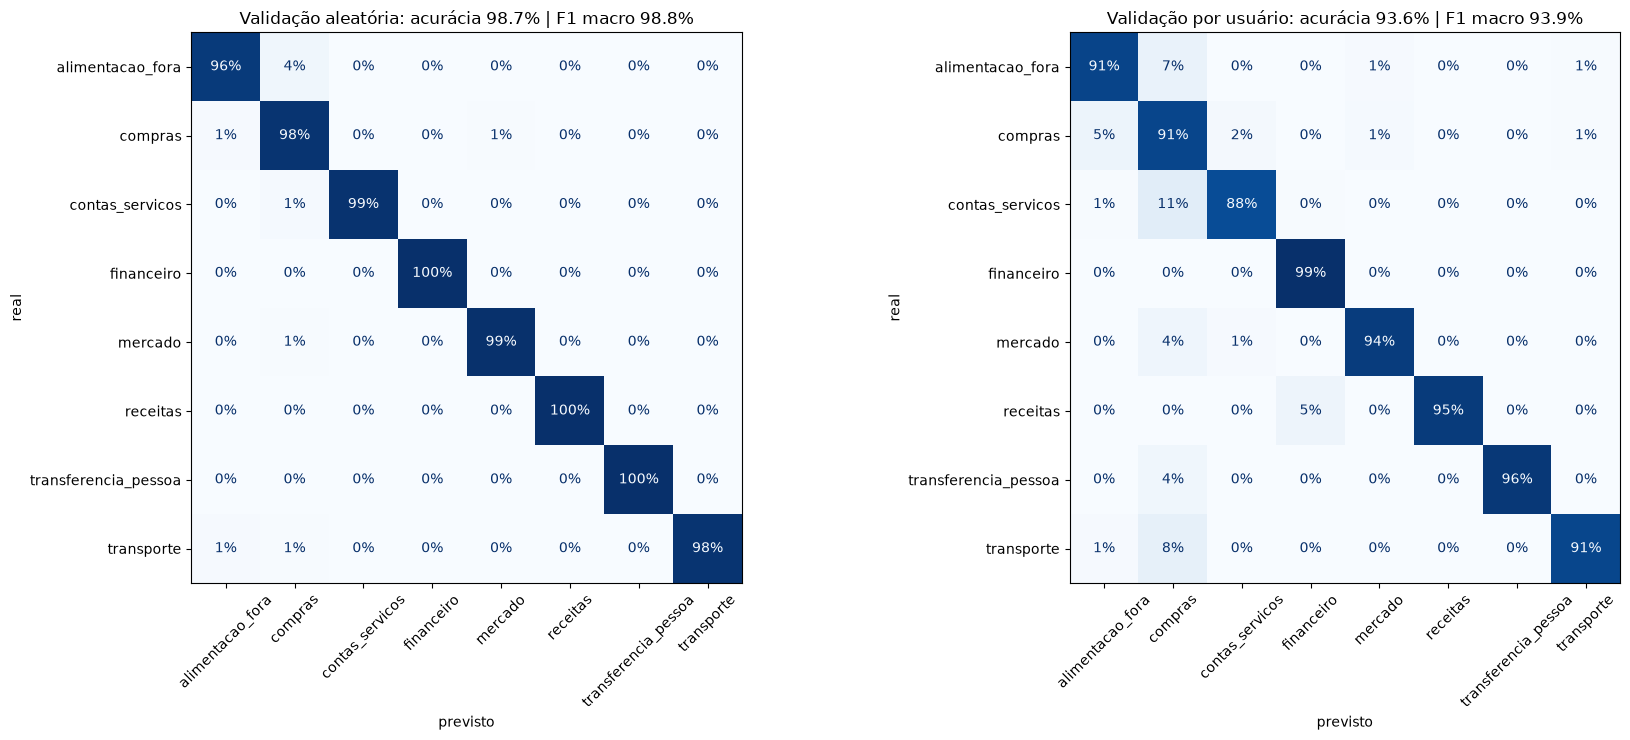

In [6]:
classes = sorted(y.unique())
fig, eixos = plt.subplots(1, 2, figsize=(18, 7.5))
for eixo, (nome, p) in zip(eixos, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y, p, labels=classes, normalize="true", values_format=".0%",
                                            cmap="Blues", colorbar=False, xticks_rotation=45, ax=eixo)
    eixo.set_title(f"Validação {nome}: acurácia {accuracy_score(y, p):.1%} | F1 macro {f1_score(y, p, average='macro'):.1%}")
    eixo.set_xlabel("previsto")
    eixo.set_ylabel("real")
plt.tight_layout()
plt.show()

## 4. Desempenho por usuário

Na validação por usuário, cada usuário é previsto por um modelo que nunca viu nenhuma transação dele.
Usuários com banco único nos dados (o histórico do banco é novo para o modelo) tendem a ir pior.

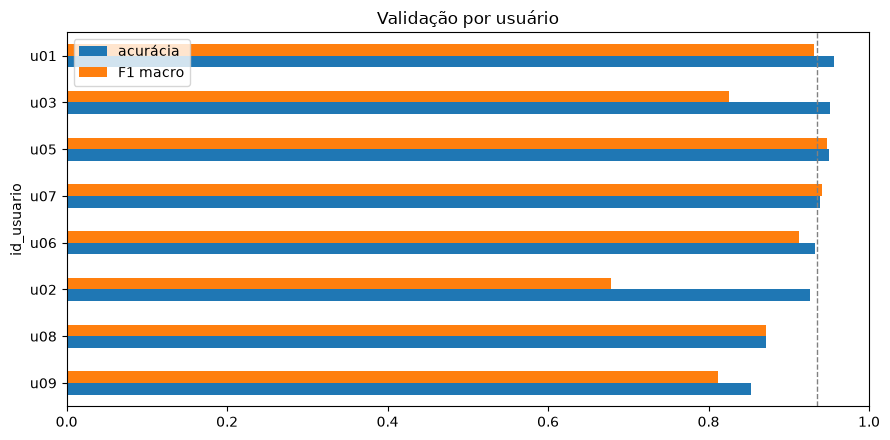

,transações,banco(s),acurácia,F1 macro
id_usuario,,,,
u09,327,santander,0.853,0.812
u08,876,nubank,0.872,0.871
u02,658,inter,0.927,0.679
u06,442,nubank,0.932,0.913
u07,2871,sicoob,0.939,0.942
u05,1094,bradesco,0.950,0.948
u03,143,nubank,0.951,0.826
u01,2878,"bradesco, nubank",0.957,0.931


In [7]:
p = pd.Series(previsoes["por usuário"], index=y.index)
por_usuario = pd.DataFrame({
    "transações": grupos.value_counts(),
    "banco(s)": df.groupby("id_usuario")["banco"].agg(lambda b: ", ".join(sorted(set(b)))),
    "acurácia": y.groupby(grupos).apply(lambda s: accuracy_score(s, p[s.index])),
    "F1 macro": y.groupby(grupos).apply(lambda s: f1_score(s, p[s.index], average="macro")),
}).sort_values("acurácia")

ax = por_usuario[["acurácia", "F1 macro"]].plot.barh(figsize=(9, 4.5), xlim=(0, 1), title="Validação por usuário")
ax.axvline(accuracy_score(y, p), color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()
por_usuario

## 5. O que o modelo aprendeu

O SVM linear dá um peso a cada atributo, por classe: peso alto = atributo que empurra para aquela classe.
Abaixo, os atributos de maior peso de cada classe, treinando com todos os dados.
(`contraparte__xyz` = pedaço de nome de loja; `cat__meio_pix` = meio igual a pix; etc.)

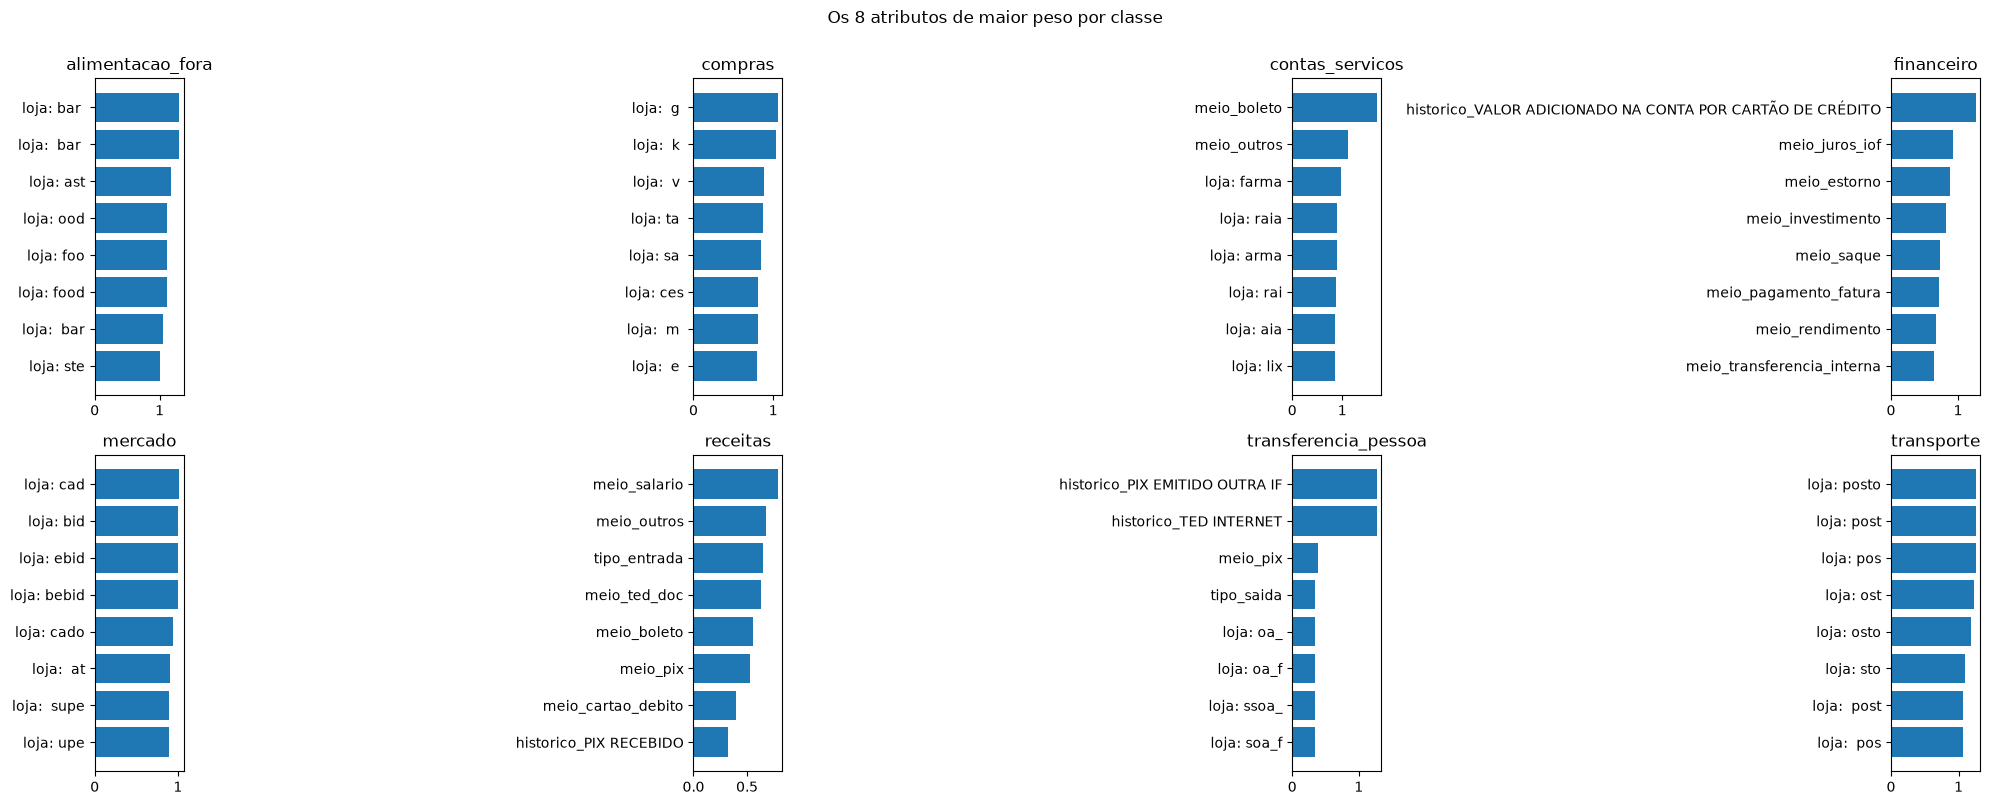

In [8]:
final = monta_modelo().fit(X, y)
nomes = final.named_steps["prep"].get_feature_names_out()
pesos = final.named_steps["clf"].coef_  # uma linha por classe

N = 8
fig, eixos = plt.subplots(2, 4, figsize=(20, 8))
for eixo, classe, w in zip(eixos.ravel(), final.classes_, pesos):
    topo = np.argsort(w)[-N:]
    eixo.barh([nomes[i].replace("contraparte__", "loja: ").replace("cat__", "").replace("valor__", "")
               for i in topo], w[topo], color="tab:blue")
    eixo.set_title(classe)
plt.suptitle(f"Os {N} atributos de maior peso por classe", y=1.0)
plt.tight_layout()
plt.show()

## 6. Onde ele erra

Pares (real → previsto) mais frequentes na validação por usuário. O padrão esperado: quando não reconhece
a loja de um usuário novo, o modelo tende a `compras`.

In [9]:
erros = df.assign(previsto=previsoes["por usuário"]).query("categoria != previsto")
print(f"{len(erros)} erros de {len(df)} ({len(erros) / len(df):.1%})")
erros.groupby(["categoria", "previsto", "meio"]).size().sort_values(ascending=False).head(12).to_frame("erros")

598 erros de 9289 (6.4%)


,,,erros
categoria,previsto,meio,
transferencia_pessoa,compras,pix,65
alimentacao_fora,compras,cartao_debito,57
contas_servicos,compras,cartao_credito,54
compras,alimentacao_fora,cartao_credito,52
receitas,financeiro,salario,40
mercado,compras,cartao_debito,34
compras,alimentacao_fora,cartao_debito,31
contas_servicos,compras,pix,31
transporte,compras,pix,29


## 7. Modelo final (`.pkl`)

Treina com **todas** as transações rotuladas e salva em `ml/modelos/svm_tfidf.pkl` (fora do git).
É o mesmo que `python -m ml.train`.

In [10]:
import joblib

from ml.train import train_model as treina

pkl = RAIZ / "ml" / "modelos" / "svm_tfidf.pkl"
modelo_final, n = treina(CSV)
pkl.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo_final, pkl)
print(f"treinado com {n} transações e salvo em {pkl}")

# uso: recebe o CSV do parser (sem categoria) e devolve a categoria
carregado = joblib.load(pkl)
pd.Series(carregado.predict(X.head(10)), name="categoria_prevista").to_frame()

treinado com 9289 transações e salvo em c:\Users\pedro\OneDrive\Área de Trabalho\Projeto-TCS-final\ml\modelos\svm_tfidf.pkl


,categoria_prevista
0,compras
1,compras
2,compras
3,contas_servicos
4,compras
5,compras
6,alimentacao_fora
7,alimentacao_fora
8,transporte
9,alimentacao_fora
